<a href="https://colab.research.google.com/github/FaridHdz/-C-digo-de-robot-manipulador-planar-de-2-grados-de-libertad-/blob/main/Codigo_fuente_para_simular_un_robot_planar_de_2_GDL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Integración exitosa: True


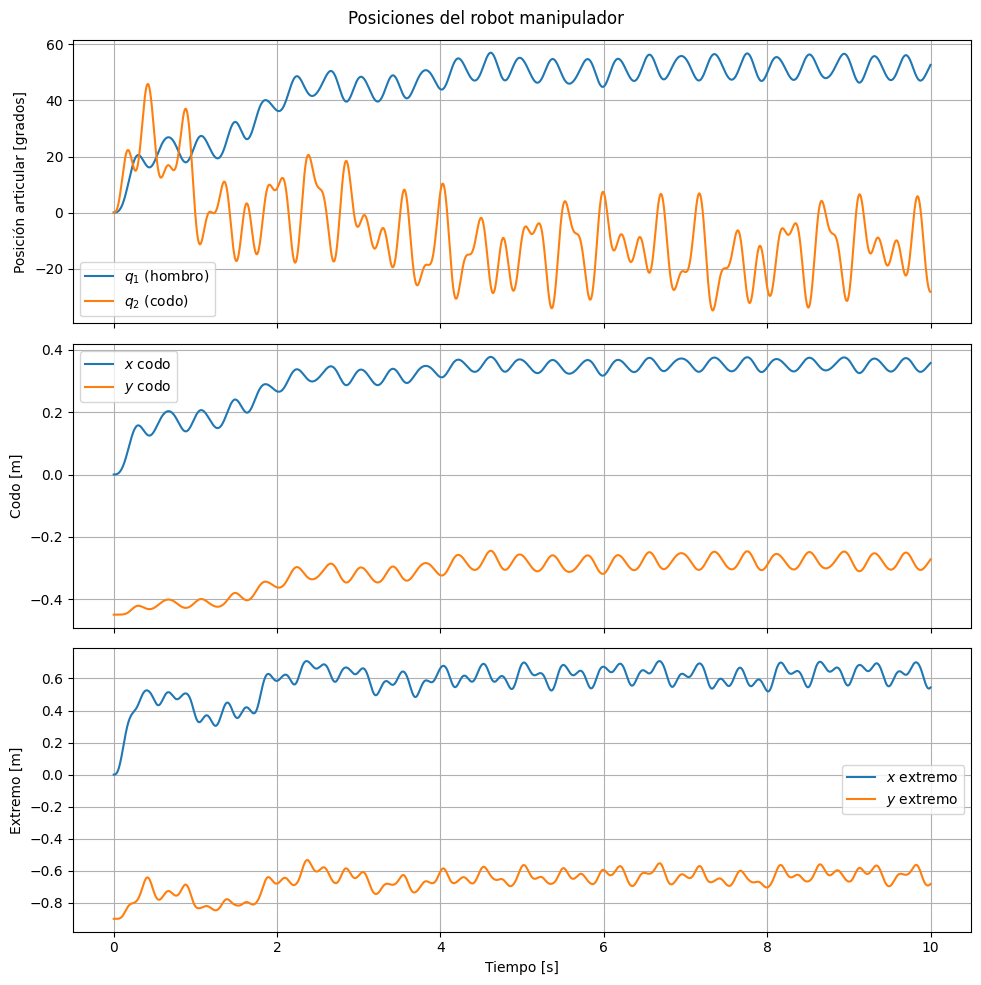

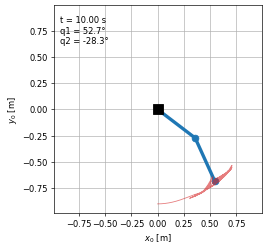

In [10]:
# -----------------------------------------------------------------
# SIMULACIÓN DE UN ROBOT PLANAR DE 2 GDL (Versión en Python)
# -----------------------------------------------------------------
# FARID ALEJANDRO CHEVEZ HERNANDEZ
# AZUCENA FLORENCIO SANTIAGO
# MARIANA PEREZ HERRERA
# HECTOR DE JESUS SOBREVILLA
# ROBERTO
#
# Parámetros: Código fuente 5.5 (F. Reyes Cortés, Robótica. Control de
# robots manipuladores, Alfaomega). q = 0 -> eslabones colgando hacia -y0.

import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter

# Longitudes: SOLO para dibujar el robot (la dinámica no las usa)
l1, l2 = 0.45, 0.45   # [m]

# Definicion de los pares aplicados del robot
def tau(t):
    tau1 = (1 - np.exp(-0.8*t))*32 + 56*np.sin(16*t + 0.1) + 12*np.sin(20*t + 0.15)
    tau2 = (1 - np.exp(-1.8*t))*1.2 + 8*np.sin(26*t + 0.08) + 2*np.sin(12*t + 0.34)
    return np.array([tau1, tau2])

# Dinamica del robot
def f(t, x):
    q1, q2, qp1, qp2 = x
    qp = np.array([qp1, qp2])

    # Matriz de inercia
    M = np.array([[3.117 + 0.2*np.cos(q2), 0.108 + 0.1*np.cos(q2)],
                  [0.108 + 0.1*np.cos(q2), 0.108]])

    # Matriz de fuerzas centrípetas y de Coriolis
    C = np.array([[-0.2*np.sin(q2)*qp2, -0.1*np.sin(q2)*qp2],
                  [ 0.1*np.sin(q2)*qp1,  0.0]])

    # Pares gravitacionales
    par_grav = np.array([39.3*np.sin(q1) + 1.95*np.sin(q1 + q2),
                         1.95*np.sin(q1 + q2)])

    # Fricción viscosa + Coulomb
    fr = np.array([1.86*qp1 + 1.93*np.sign(qp1),
                   0.16*qp2 + 0.3*np.sign(qp2)])

    qpp = np.linalg.solve(M, tau(t) - C @ qp - par_grav - fr)
    return [qp1, qp2, qpp[0], qpp[1]]

# ----------------- Simulación (10 s) -----------------
T = 10.0
h = 0.0025
t = np.arange(0, T + h/2, h)
x0 = [0.0, 0.0, 0.0, 0.0]

sol = solve_ivp(f, (0, T), x0, t_eval=t, method='RK45', rtol=1e-3, max_step=h)
q1, q2, qp1, qp2 = sol.y
print("Integración exitosa:", sol.success)

# Cinemática directa
x_codo = l1*np.sin(q1);              y_codo = -l1*np.cos(q1)
x_ext  = x_codo + l2*np.sin(q1+q2);  y_ext  = y_codo - l2*np.cos(q1+q2)

# ----------------- Gráficas -----------------
fig, ax = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
ax[0].plot(t, np.degrees(q1), label='$q_1$ (hombro)')
ax[0].plot(t, np.degrees(q2), label='$q_2$ (codo)')
ax[0].set_ylabel('Posición articular [grados]'); ax[0].legend(); ax[0].grid()

ax[1].plot(t, x_codo, label='$x$ codo'); ax[1].plot(t, y_codo, label='$y$ codo')
ax[1].set_ylabel('Codo [m]'); ax[1].legend(); ax[1].grid()

ax[2].plot(t, x_ext, label='$x$ extremo'); ax[2].plot(t, y_ext, label='$y$ extremo')
ax[2].set_ylabel('Extremo [m]'); ax[2].set_xlabel('Tiempo [s]')
ax[2].legend(); ax[2].grid()
plt.suptitle('Posiciones del robot manipulador')
plt.tight_layout()

# ----------------- Animación -----------------
#La animacion se visualiza de mejor manera en VSC
fps = 15
idx = [np.argmin(np.abs(t - ta)) for ta in np.arange(0, T + 1e-9, 1/fps)]

fig_a, ax_a = plt.subplots(figsize=(4.5, 4.5), dpi=60)
lim = (l1 + l2)*1.1
ax_a.set_xlim(-lim, lim); ax_a.set_ylim(-lim, lim)
ax_a.set_aspect('equal'); ax_a.grid()
ax_a.set_xlabel('$x_0$ [m]'); ax_a.set_ylabel('$y_0$ [m]')
brazo, = ax_a.plot([], [], '-o', lw=4, color='tab:blue', ms=8)
traza, = ax_a.plot([], [], '-', lw=1, color='tab:red', alpha=0.6)
ax_a.plot(0, 0, 'ks', ms=12)
texto = ax_a.text(0.03, 0.95, '', transform=ax_a.transAxes, va='top')

def update(k):
    i = idx[k]
    brazo.set_data([0, x_codo[i], x_ext[i]], [0, y_codo[i], y_ext[i]])
    traza.set_data(x_ext[:i+1], y_ext[:i+1])
    texto.set_text(f't = {t[i]:.2f} s\nq1 = {np.degrees(q1[i]):.1f}°\nq2 = {np.degrees(q2[i]):.1f}°')
    return brazo, traza, texto

anim = FuncAnimation(fig_a, update, frames=len(idx), blit=True)
anim.save('robot_2gdl.gif', writer=PillowWriter(fps=fps))

plt.show()